In [1]:
import torch
import torch.nn.functional as F
import torch.nn as nn
from torch_geometric.nn import GATConv
from torch_geometric.data import Data
import matplotlib.pyplot as plt
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# GAT Model same architecture as notebook 04
class FraudGAT(nn.Module):
    def __init__(self, in_channels, hidden=64, out=2, heads=4, dropout=0.3):
        super().__init__()
        self.gat1 = GATConv(in_channels, hidden, heads=heads, dropout=dropout)
        self.gat2 = GATConv(hidden*heads, hidden, heads=2, dropout=dropout)
        self.gat3 = GATConv(hidden*2, out, heads=1, concat=False, dropout=dropout)
        self.drop = dropout
    def forward(self, x, edge_index):
        x = F.dropout(x, p=self.drop, training=self.training)
        x = F.elu(self.gat1(x, edge_index))
        x = F.dropout(x, p=self.drop, training=self.training)
        x = F.elu(self.gat2(x, edge_index))
        x = F.dropout(x, p=self.drop, training=self.training)
        return self.gat3(x, edge_index)

# Load graph
data = torch.load('outputs/ibm_graph.pt', weights_only=False)

# Same stratified subgraph as notebook 04
torch.manual_seed(42)
np.random.seed(42)

TRAIN_FRAUD=1500; TRAIN_LEGIT=4500
VAL_FRAUD=500;   VAL_LEGIT=1500
TEST_FRAUD=500;  TEST_LEGIT=1500

train_idx = torch.where(data.train_mask)[0]
val_idx   = torch.where(data.val_mask)[0]
test_idx  = torch.where(data.test_mask)[0]

def sample_nodes(fraud_n, legit_n, nf, nl):
    nf = min(nf, len(fraud_n))
    nl = min(nl, len(legit_n))
    return torch.cat([
        fraud_n[torch.randperm(len(fraud_n))[:nf]],
        legit_n[torch.randperm(len(legit_n))[:nl]]
    ])

train_fraud = train_idx[data.y[train_idx]==1]
train_legit = train_idx[data.y[train_idx]==0]
val_fraud   = val_idx[data.y[val_idx]==1]
val_legit   = val_idx[data.y[val_idx]==0]
test_fraud  = test_idx[data.y[test_idx]==1]
test_legit  = test_idx[data.y[test_idx]==0]

sel_train = sample_nodes(train_fraud, train_legit, TRAIN_FRAUD, TRAIN_LEGIT)
sel_val   = sample_nodes(val_fraud, val_legit, VAL_FRAUD, VAL_LEGIT)
sel_test  = sample_nodes(test_fraud, test_legit, TEST_FRAUD, TEST_LEGIT)
sel_nodes = torch.unique(torch.cat([sel_train, sel_val, sel_test]))

old_to_new = torch.full((data.num_nodes,), -1, dtype=torch.long)
old_to_new[sel_nodes] = torch.arange(len(sel_nodes))

src, dst  = data.edge_index[0], data.edge_index[1]
emask = (old_to_new[src]>=0) & (old_to_new[dst]>=0)
new_ei = torch.stack([old_to_new[src[emask]], old_to_new[dst[emask]]], dim=0)

sub_data = Data(
    x=data.x[sel_nodes], y=data.y[sel_nodes], edge_index=new_ei
)
sub_data.train_mask = torch.zeros(len(sel_nodes), dtype=torch.bool)
sub_data.val_mask   = torch.zeros(len(sel_nodes), dtype=torch.bool)
sub_data.test_mask  = torch.zeros(len(sel_nodes), dtype=torch.bool)
sub_data.train_mask[old_to_new[sel_train]] = True
sub_data.val_mask[old_to_new[sel_val]]     = True
sub_data.test_mask[old_to_new[sel_test]]   = True

# Load trained model
model = FraudGAT(in_channels=sub_data.num_node_features)
model.load_state_dict(torch.load('outputs/fraud_gat_model.pt', weights_only=True))
model.eval()

print("✅ Everything loaded!")
print(f"Nodes:    {sub_data.num_nodes:,}")
print(f"Features: {sub_data.num_node_features}")
print(f"Fraud:    {(sub_data.y==1).sum().item():,}")

✅ Everything loaded!
Nodes:    10,000
Features: 13
Fraud:    2,500


In [2]:
from torch_geometric.explain import Explainer, GNNExplainer

explainer = Explainer(
    model            = model,
    algorithm        = GNNExplainer(epochs=200),
    explanation_type = 'model',
    node_mask_type   = 'attributes',
    edge_mask_type   = 'object',
    model_config     = dict(
        mode        = 'multiclass_classification',
        task_level  = 'node',
        return_type = 'raw'
    )
)

# Fraud nodes in test set
test_fraud_nodes = (
    (sub_data.y == 1) & sub_data.test_mask
).nonzero(as_tuple=True)[0]

print(f"Fraud nodes in test: {len(test_fraud_nodes)}")

target_node = test_fraud_nodes[0].item()
print(f"Explaining node: {target_node}")

explanation = explainer(
    sub_data.x,
    sub_data.edge_index,
    index=target_node
)

feat_importance = explanation.node_mask[target_node].detach().numpy()
feat_importance = feat_importance / feat_importance.sum()

print("✅ Explanation generated!")
print(f"Feature importances: {feat_importance.round(4)}")

Fraud nodes in test: 500
Explaining node: 4
✅ Explanation generated!
Feature importances: [0.0636 0.057  0.0615 0.0625 0.0609 0.0639 0.0607 0.0623 0.0637 0.2531
 0.0572 0.0639 0.0697]


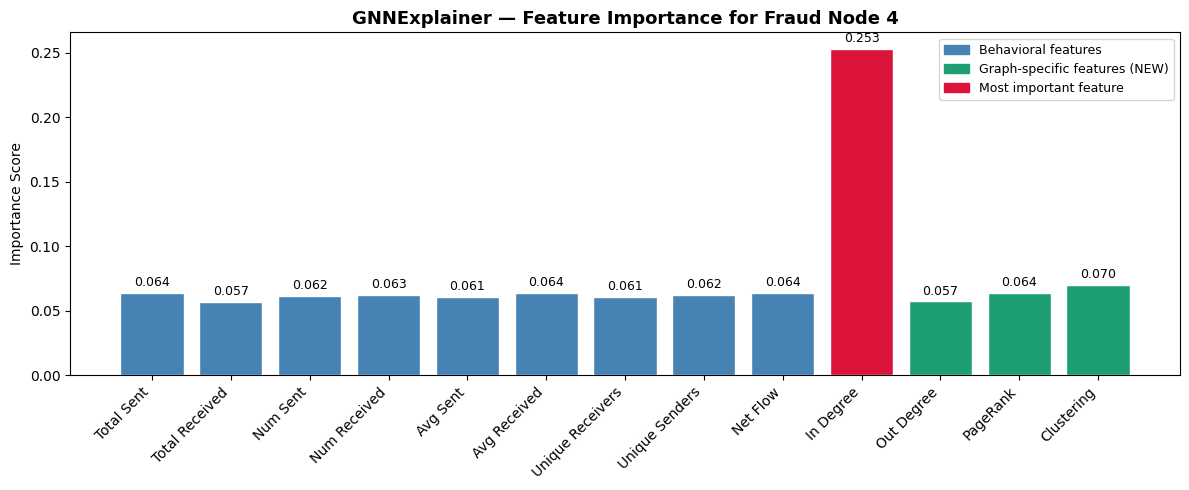

✅ Feature importance plot saved!


In [3]:
feature_names = [
    'Total Sent', 'Total Received',
    'Num Sent', 'Num Received',
    'Avg Sent', 'Avg Received',
    'Unique Receivers', 'Unique Senders',
    'Net Flow',
    'In Degree', 'Out Degree',    # Graph features
    'PageRank', 'Clustering'       # Graph features
]

colors = ['crimson' if f == feat_importance.max()
          else '#1D9E75' if i >= 9    # Graph features green
          else 'steelblue'
          for i, f in enumerate(feat_importance)]

plt.figure(figsize=(12, 5))
bars = plt.bar(feature_names, feat_importance,
               color=colors, edgecolor='white')
plt.title(f'GNNExplainer — Feature Importance for Fraud Node {target_node}',
          fontsize=13, fontweight='bold')
plt.ylabel('Importance Score')
plt.xticks(rotation=45, ha='right')

for bar, val in zip(bars, feat_importance):
    plt.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.003,
             f'{val:.3f}', ha='center', va='bottom', fontsize=9)

# Legend
import matplotlib.patches as mpatches
patches = [
    mpatches.Patch(color='steelblue',  label='Behavioral features'),
    mpatches.Patch(color='#1D9E75',    label='Graph-specific features (NEW)'),
    mpatches.Patch(color='crimson',    label='Most important feature'),
]
plt.legend(handles=patches, fontsize=9)
plt.tight_layout()
plt.savefig('outputs/gnnexplainer_features.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Feature importance plot saved!")

In [4]:
import shap
from sklearn.ensemble import GradientBoostingClassifier

print("Getting GNN predictions...")
model.eval()
with torch.no_grad():
    out  = model(sub_data.x, sub_data.edge_index)
    pred = out.argmax(dim=1).numpy()

X_all = sub_data.x.numpy()

print("Training surrogate model...")
surrogate = GradientBoostingClassifier(
    n_estimators=100, max_depth=4, random_state=42
)
surrogate.fit(X_all, pred)
print(f"Surrogate accuracy: {surrogate.score(X_all, pred)*100:.1f}%")

fraud_idx = (sub_data.y==1).nonzero(as_tuple=True)[0].numpy()
test_input = X_all[fraud_idx[:30]]

print("Running SHAP...")
shap_explainer = shap.TreeExplainer(surrogate)
shap_values    = shap_explainer.shap_values(test_input)
shap_vals      = shap_values[1] if isinstance(shap_values, list) else shap_values
base_val       = float(shap_explainer.expected_value[0]
                       if isinstance(shap_explainer.expected_value, (list, np.ndarray))
                       else shap_explainer.expected_value)
print("✅ SHAP done!")

Getting GNN predictions...
Training surrogate model...
Surrogate accuracy: 96.2%
Running SHAP...
✅ SHAP done!


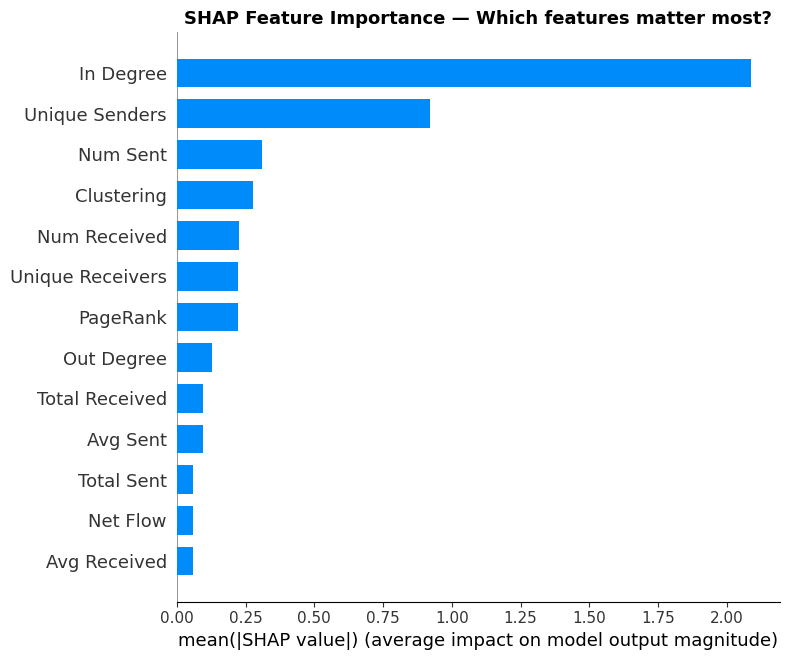

✅ SHAP bar plot saved!


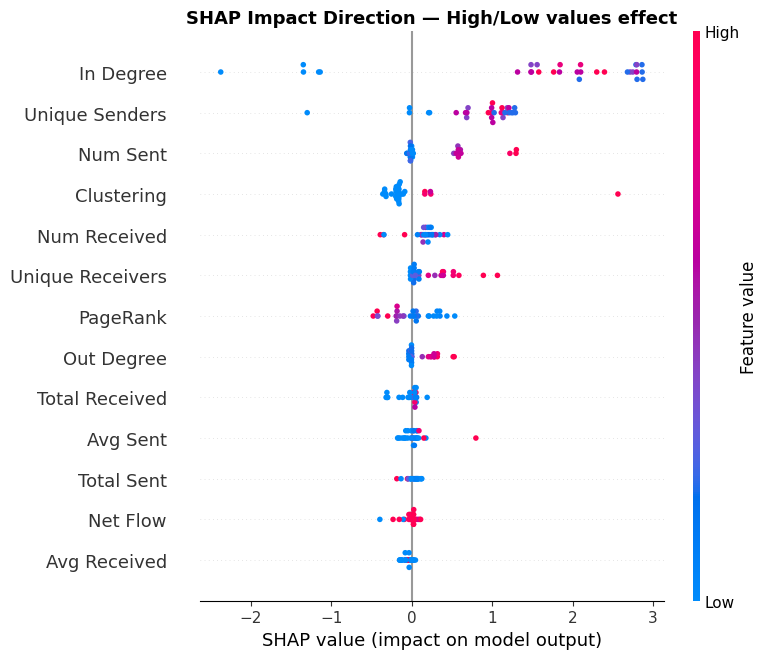

✅ SHAP dot plot saved!


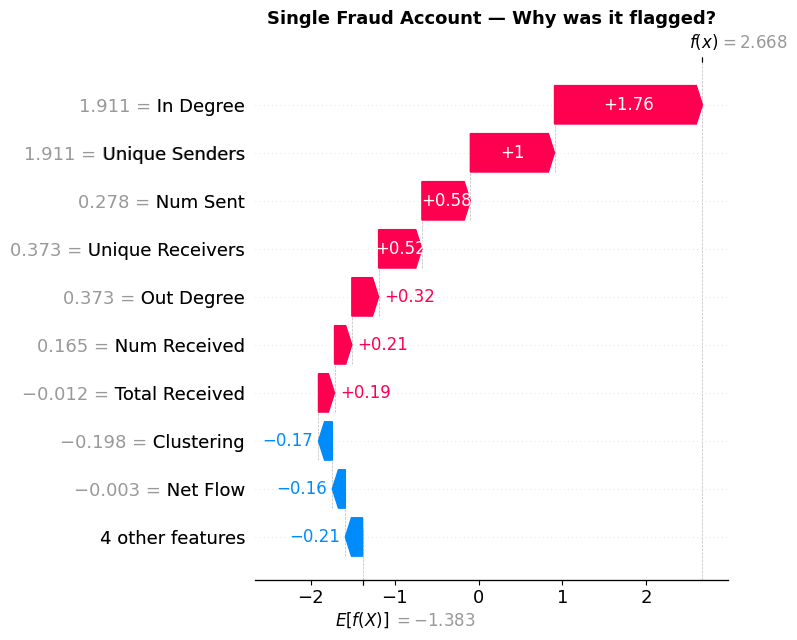

✅ Waterfall plot saved!

🎉 All SHAP plots complete!


In [5]:
# Plot 1: Bar
plt.figure(figsize=(10, 5))
shap.summary_plot(shap_vals, test_input,
                  feature_names=feature_names,
                  show=False, plot_type='bar')
plt.title('SHAP Feature Importance — Which features matter most?',
          fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('outputs/shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ SHAP bar plot saved!")

# Plot 2: Dot
plt.figure(figsize=(10, 5))
shap.summary_plot(shap_vals, test_input,
                  feature_names=feature_names, show=False)
plt.title('SHAP Impact Direction — High/Low values effect',
          fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('outputs/shap_dot_plot.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ SHAP dot plot saved!")

# Plot 3: Waterfall
plt.figure(figsize=(11, 5))
shap.waterfall_plot(
    shap.Explanation(
        values        = shap_vals[0],
        base_values   = base_val,
        data          = test_input[0],
        feature_names = feature_names
    ), show=False
)
plt.title('Single Fraud Account — Why was it flagged?',
          fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('outputs/shap_waterfall.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Waterfall plot saved!")
print("\n🎉 All SHAP plots complete!")

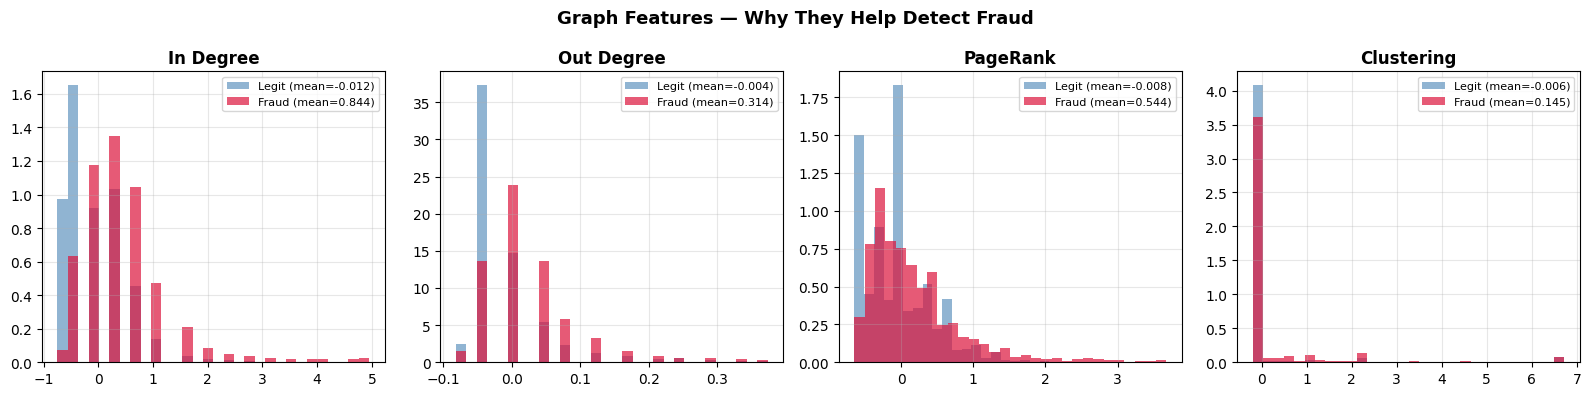

✅ Graph features impact plot saved!

Note: Fraud accounts have different PageRank and Degree distributions
This proves graph structure helps in fraud detection!


In [6]:
# Ye plot dikhata hai ki graph features (PageRank, Degree)
# fraud accounts mein alag hote hain

feature_names_short = [
    'Total Sent', 'Total Received',
    'Num Sent', 'Num Received',
    'Avg Sent', 'Avg Received',
    'Unique Rcv', 'Unique Snd',
    'Net Flow',
    'In Degree', 'Out Degree',
    'PageRank', 'Clustering'
]

fraud_mask = sub_data.y.numpy() == 1
legit_mask = sub_data.y.numpy() == 0

# Graph features only (index 9-12)
graph_feat_idx  = [9, 10, 11, 12]
graph_feat_names = ['In Degree', 'Out Degree', 'PageRank', 'Clustering']

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
fig.suptitle('Graph Features — Why They Help Detect Fraud',
             fontsize=13, fontweight='bold')

for ax, idx, name in zip(axes, graph_feat_idx, graph_feat_names):
    fraud_vals = X_all[fraud_mask, idx]
    legit_vals = X_all[legit_mask, idx]

    p99 = np.percentile(
        np.concatenate([fraud_vals, legit_vals]), 99
    )

    ax.hist(legit_vals[legit_vals<=p99], bins=30,
            color='steelblue', alpha=0.6,
            label=f'Legit (mean={legit_vals.mean():.3f})', density=True)
    ax.hist(fraud_vals[fraud_vals<=p99], bins=30,
            color='crimson', alpha=0.7,
            label=f'Fraud (mean={fraud_vals.mean():.3f})', density=True)
    ax.set_title(name, fontweight='bold')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('outputs/graph_features_impact.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("✅ Graph features impact plot saved!")
print("\nNote: Fraud accounts have different PageRank and Degree distributions")
print("This proves graph structure helps in fraud detection!")